# DSC 630 Project Milestones

## Load and review the data

In [1]:
import pandas as pd
import numpy as np

In [2]:
telco_churn = pd.read_excel("telco_customer_churn.xlsx")

print(telco_churn.info())
telco_churn.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [9]:
import dataframe_image as dfi

subset = telco_churn.iloc[:, :10] 

dfi.export(
    subset.head(), 
    "telco_churn.png", 
    table_conversion = "matplotlib")

In [3]:
#telco_churn["Count"].unique()

In [4]:
#check for missing values
telco_churn.isna().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

The variable Churn Reason contains a large number of missing values because it is only recorded for customers who have already churned. Since this information is unavailable prior to churn and would not be known at the time of prediction, the variable was excluded from the predictive modeling process to avoid data leakage. 

Churn Label: 
- Yes = the customer left the company this quarter
- No = the customer remained with the company

Churn Value: 
- 1 = the customer left the company this quarter
- 0 = the customer remained with the company

In [5]:
#target distribution
telco_churn["Churn Label"].value_counts(normalize = True)

Churn Label
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64

In [6]:
#encode Churn Label target variable
telco_churn["Churn_binary"] = telco_churn["Churn Label"].map({"Yes": 1, "No": 0})

In [7]:
#drop non-needed columns for modeling
telco_churn = telco_churn.drop(columns = ["CustomerID", "Count", "Churn Label", "Churn Score", "CLTV", "Churn Reason"])

CustomerID: A unique ID that identifies each customer.

Count: A value used in reporting/dashboarding to sum up the number of customers in a filtered set.

Churn Label: Yes = the customer left the company this quarter. No = the customer remained with the company. Directly related to Churn Value.

Churn Score: A value from 0-100 that is calculated using the predictive tool IBM SPSS Modeler. The model incorporates multiple factors known to cause churn. The higher the score, the more likely the customer will churn.

CLTV: Customer Lifetime Value. A predicted CLTV is calculated using corporate formulas and existing data. The higher the value, the more valuable the customer. High value customers should be monitored for churn.

Churn Reason: A customer’s specific reason for leaving the company. Directly related to Churn Category.

In [8]:
#convert Total Charges to numeric
telco_churn["Total Charges"] = pd.to_numeric(telco_churn["Total Charges"], errors = "coerce")

In [9]:
#reheck for missing values after transformations
telco_churn.isna().sum()

Country               0
State                 0
City                  0
Zip Code              0
Lat Long              0
Latitude              0
Longitude             0
Gender                0
Senior Citizen        0
Partner               0
Dependents            0
Tenure Months         0
Phone Service         0
Multiple Lines        0
Internet Service      0
Online Security       0
Online Backup         0
Device Protection     0
Tech Support          0
Streaming TV          0
Streaming Movies      0
Contract              0
Paperless Billing     0
Payment Method        0
Monthly Charges       0
Total Charges        11
Churn Value           0
Churn_binary          0
dtype: int64

In [10]:
#drop new NAs for Total Charges
telco_churn = telco_churn.dropna()

#reheck for missing values
telco_churn.isna().sum()

Country              0
State                0
City                 0
Zip Code             0
Lat Long             0
Latitude             0
Longitude            0
Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn Value          0
Churn_binary         0
dtype: int64

## EDA

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

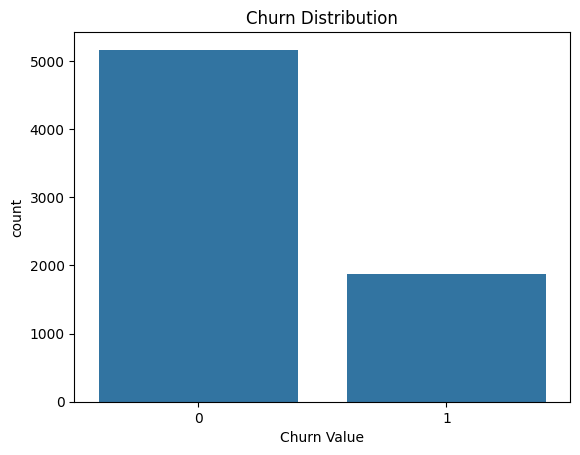

In [13]:
sns.countplot(data = telco_churn, x = "Churn Value")
plt.title("Churn Distribution")

#plt.savefig("Churn_Distribution.png", dpi = 300, bbox_inches = "tight")

plt.show()

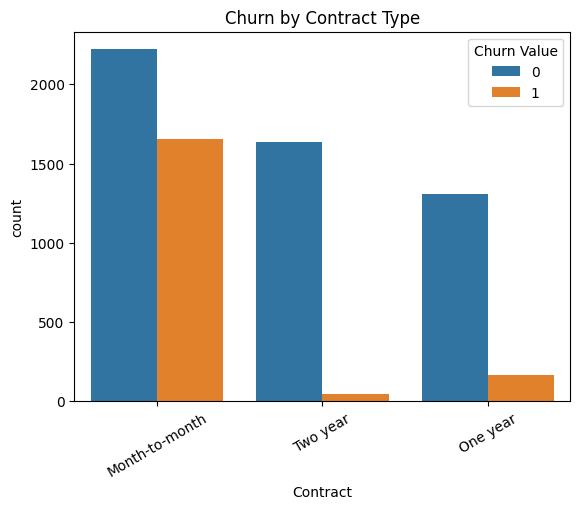

In [16]:
sns.countplot(data = telco_churn, x = "Contract", hue = "Churn Value")
plt.title("Churn by Contract Type")
plt.xticks(rotation = 30)

#plt.savefig("Churn_by_Contract.png", dpi = 300, bbox_inches = "tight") 

plt.show()

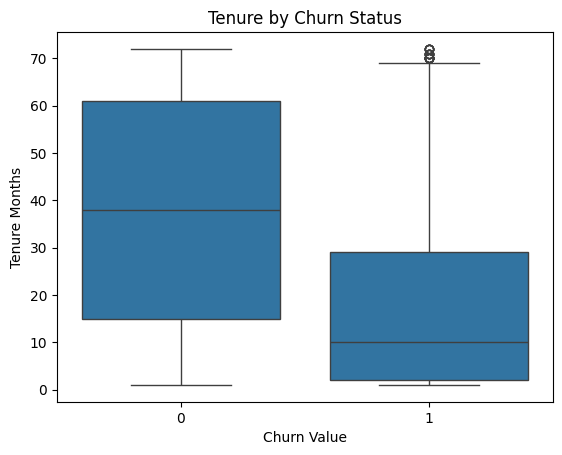

In [15]:
sns.boxplot(data = telco_churn, x = "Churn Value", y = "Tenure Months")
plt.title("Tenure by Churn Status")

#plt.savefig("Tenure_by_Churn.png", dpi = 300, bbox_inches = "tight")

plt.show()

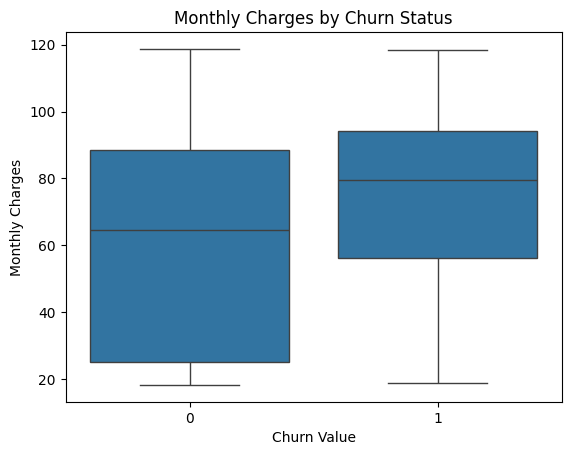

In [17]:
sns.boxplot(data = telco_churn, x = "Churn Value", y = "Monthly Charges")
plt.title("Monthly Charges by Churn Status")

#plt.savefig("MonthChrg_by_Churn.png", dpi = 300, bbox_inches = "tight") 

plt.show()

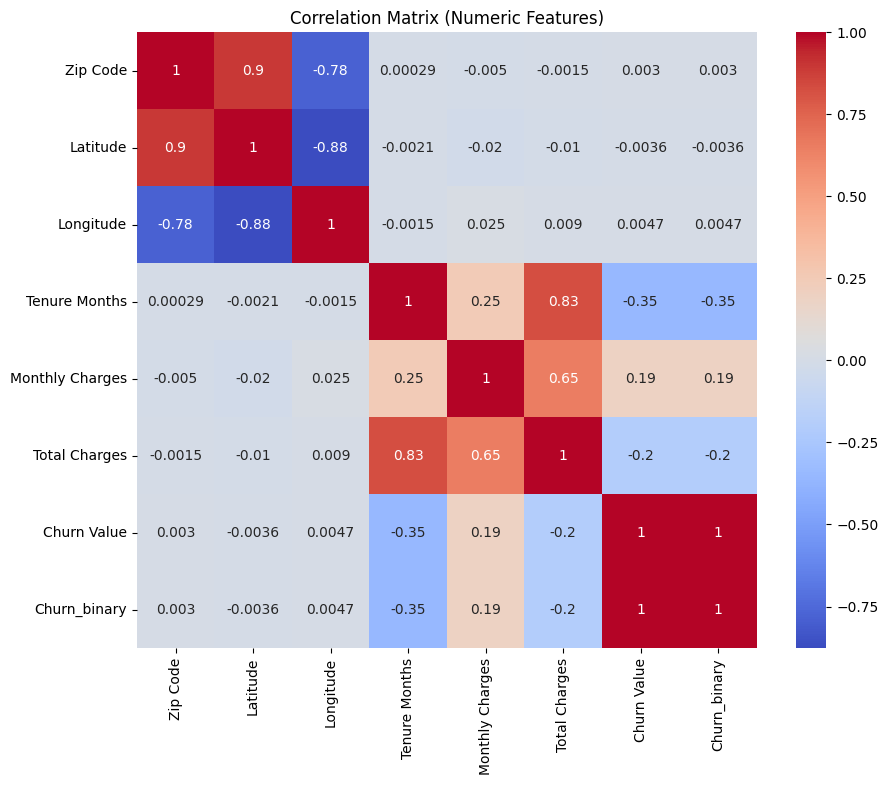

In [18]:
numeric_cols = telco_churn.select_dtypes(include = ["int64", "float64"])

plt.figure(figsize = (10, 8))
sns.heatmap(numeric_cols.corr(), annot = True, cmap = "coolwarm")
plt.title("Correlation Matrix (Numeric Features)")

#plt.savefig("Corr_Matrix.png", dpi = 300, bbox_inches = "tight")

plt.show()

## Feature Encoding

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features and target
X = telco_churn.drop(columns = ["Churn Value", "Churn_binary"])
y = telco_churn["Churn_binary"]

# One-hot encode categorical variables
X_encoded = pd.get_dummies(X, drop_first = True)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size = 0.3, random_state = 42, stratify = y)

# Scale numeric features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Baseline logistic regression

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

log_reg = LogisticRegression(max_iter = 1000)
log_reg.fit(X_train_scaled, y_train)

y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

#evaluation
confusion_matrix(y_test, y_pred)

print(classification_report(y_test, y_pred))
print(f" Log Regression ROC AUC Score: {roc_auc_score(y_test, y_proba)}")

              precision    recall  f1-score   support

           0       0.79      0.81      0.80      1549
           1       0.44      0.41      0.42       561

    accuracy                           0.70      2110
   macro avg       0.61      0.61      0.61      2110
weighted avg       0.70      0.70      0.70      2110

 Log Regression ROC AUC Score: 0.7041585106370736


## Log regression with updated class_weight

In [21]:
log_reg_balanced = LogisticRegression(max_iter = 1000, class_weight = "balanced")
log_reg_balanced.fit(X_train_scaled, y_train)

y_pred_balanced = log_reg_balanced.predict(X_test_scaled)
y_proba_balanced = log_reg_balanced.predict_proba(X_test_scaled)[:, 1]

#evaluation
confusion_matrix(y_test, y_pred)

print(classification_report(y_test, y_pred_balanced))
print(f" Log Regression (Balanced) ROC AUC Score: {roc_auc_score(y_test, y_proba_balanced)}")

              precision    recall  f1-score   support

           0       0.81      0.78      0.79      1549
           1       0.44      0.48      0.46       561

    accuracy                           0.70      2110
   macro avg       0.62      0.63      0.63      2110
weighted avg       0.71      0.70      0.70      2110

 Log Regression (Balanced) ROC AUC Score: 0.7083875630186343


## Simple tree model (non-linearity check)

In [22]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth = 5, class_weight = "balanced", random_state = 42)

tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
tree_proba = tree.predict_proba(X_test)[:, 1]

print(classification_report(y_test, tree_pred))
print(f"Tree ROC AUC Score: {roc_auc_score(y_test, tree_proba)}")   

              precision    recall  f1-score   support

           0       0.91      0.68      0.78      1549
           1       0.48      0.82      0.61       561

    accuracy                           0.72      2110
   macro avg       0.70      0.75      0.69      2110
weighted avg       0.80      0.72      0.73      2110

Tree ROC AUC Score: 0.8269057490946375


## Random Forest

In [23]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators = 200,    
    random_state = 42,
    class_weight = "balanced") 

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))
print(f"Random Forest ROC AUC Score: {roc_auc_score(y_test, y_proba_rf)}")

[[1396  153]
 [ 275  286]]
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1549
           1       0.65      0.51      0.57       561

    accuracy                           0.80      2110
   macro avg       0.74      0.71      0.72      2110
weighted avg       0.79      0.80      0.79      2110

Random Forest ROC AUC Score: 0.8366463787228607


## Feature importance (tree-based)

In [24]:
feature_importance = pd.Series(tree.feature_importances_, index = X_train.columns).sort_values(ascending = False)

feature_importance.head(10)

Contract_Two year                  0.372832
Contract_One year                  0.232665
Dependents_Yes                     0.137926
Tenure Months                      0.085698
Internet Service_Fiber optic       0.071390
Streaming Movies_Yes               0.029614
Monthly Charges                    0.027041
Zip Code                           0.016312
Total Charges                      0.008403
Payment Method_Electronic check    0.007483
dtype: float64

## Model Comparison Table

In [25]:
model_results = {
    "Logistic Regression": {
        "Recall (Churn)": 0.41,
        "Precision (Churn)": 0.44,
        "ROC-AUC": 0.70,
        "Accuracy": 0.70},
    "Logistic (Balanced)": {
        "Recall (Churn)": 0.48,
        "Precision (Churn)": 0.44,
        "ROC-AUC": 0.71,
        "Accuracy": 0.70},
    "Decision Tree": {
        "Recall (Churn)": 0.82,
        "Precision (Churn)": 0.48,
        "ROC-AUC": 0.83,
        "Accuracy": 0.72},
    "Random Forest": {
        "Recall (Churn)": 0.51,
        "Precision (Churn)": 0.65,
        "ROC-AUC": 0.84,
        "Accuracy": 0.80}
}

In [26]:
comparison_df = pd.DataFrame(model_results).T
comparison_df

,Recall (Churn),Precision (Churn),ROC-AUC,Accuracy
Logistic Regression,0.41,0.44,0.70,0.70
Logistic (Balanced),0.48,0.44,0.71,0.70
Decision Tree,0.82,0.48,0.83,0.72
Random Forest,0.51,0.65,0.84,0.80
